In [10]:
import pandas as pd

years = [str(y) for y in range(2010, 2024)]   # 2010 to 2023
id_cols = ["Country Name", "Country Code"]

files = {
    "secure_servers":  "IT.NET.SECR.P6_DS2_en_csv_v2_8018",
    "fixed_broadband": "IT.NET.BBND.P2_DS2_en_csv_v2_1341",
    "mobile_cellular": "IT.CEL.SETS.P2_DS2_en_csv_v2_1213",
}

In [11]:
meta = pd.read_csv("Metadata_Country_API_IT.NET.SECR.P6_DS2_en_csv_v2_8018.csv")

In [12]:
frames = []
for name, code in files.items():
    df = pd.read_csv(f"API_{code}.csv", skiprows=4)
    df = df[id_cols + years]                      # keep only 2010-2023
    long = df.melt(id_vars=id_cols, var_name="Year", value_name=name)
    long["Year"] = long["Year"].astype(int)
    frames.append(long)

# combine the three indicators into one table
data = frames[0]
for f in frames[1:]:
    data = data.merge(f, on=id_cols + ["Year"], how="outer")

In [14]:
meta = pd.read_csv("Metadata_Country_API_IT.NET.SECR.P6_DS2_en_csv_v2_8018.csv")
meta = meta[["Country Code", "Region", "IncomeGroup"]].dropna(subset=["Region"])  # real countries only

data = data.merge(meta, on="Country Code", how="inner")
data.head()

,Country Name,Country Code,Year,secure_servers,fixed_broadband,mobile_cellular,Region,IncomeGroup
0,Afghanistan,AFG,2010,0.494978,0.005303,36.118681,Middle East & North Africa,Low income
1,Afghanistan,AFG,2011,0.545187,NaN,47.015184,Middle East & North Africa,Low income
2,Afghanistan,AFG,2012,1.243454,0.004908,50.196656,Middle East & North Africa,Low income
3,Afghanistan,AFG,2013,1.454651,0.004743,53.149016,Middle East & North Africa,Low income
4,Afghanistan,AFG,2014,1.738201,0.004574,56.132210,Middle East & North Africa,Low income


In [15]:
print(data.shape)
print(data["Year"].min(), data["Year"].max())
print(data.isna().sum())

(3038, 8)
2010 2023
Country Name         0
Country Code         0
Year                 0
secure_servers      60
fixed_broadband    289
mobile_cellular    205
Region               0
IncomeGroup          0
dtype: int64


In [16]:
data.to_csv("cleaned_2010_2023.csv", index=False)

In [17]:
g = data.groupby(["IncomeGroup", "Year"])["fixed_broadband"].median().unstack()
gain = (g[2023] - g[2010]).sort_values(ascending=False)
print(gain.round(1))

IncomeGroup
High income            13.5
Upper middle income    12.8
Lower middle income     1.5
Low income              0.1
dtype: float64


                     mobile_gain  fixed_gain
IncomeGroup                                 
Low income                  32.3         0.1
Lower middle income         38.8         1.5
Upper middle income         32.2        12.8
High income                 10.3        13.5


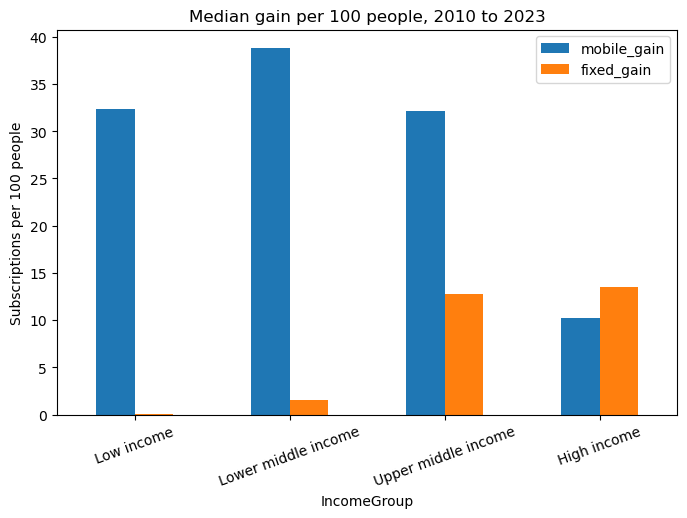

In [18]:
import matplotlib.pyplot as plt

order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
g = data.groupby(["IncomeGroup", "Year"])[["mobile_cellular", "fixed_broadband"]].median()

q1 = pd.DataFrame({
    "mobile_gain": g["mobile_cellular"].xs(2023, level="Year") - g["mobile_cellular"].xs(2010, level="Year"),
    "fixed_gain":  g["fixed_broadband"].xs(2023, level="Year") - g["fixed_broadband"].xs(2010, level="Year"),
}).reindex(order)
print(q1.round(1))

q1.plot(kind="bar", figsize=(8, 5))
plt.title("Median gain per 100 people, 2010 to 2023")
plt.ylabel("Subscriptions per 100 people")
plt.xticks(rotation=20)
plt.show()

Top 10 overall:
Year                  2010  2023  gain  low_start
Country Name                                     
Saudi Arabia           6.8  43.6  36.8      False
China                  9.3  44.7  35.4      False
Uzbekistan             0.4  30.3  29.9      False
United Arab Emirates  11.3  37.1  25.8      False
Georgia                4.7  29.3  24.6      False
Portugal              20.1  44.1  24.0      False
French Polynesia      11.9  35.6  23.6      False
Seychelles             7.2  30.8  23.6      False
Greece                20.2  43.9  23.6      False
Bulgaria              15.1  37.0  21.9      False

Top 10 among countries that started in the bottom quarter:
Year                  2010  2023  gain  low_start
Country Name                                     
Iraq                   0.0  17.2  17.2       True
Nepal                  0.2  10.7  10.5       True
Bangladesh             0.3   7.9   7.6       True
Syrian Arab Republic   0.3   6.9   6.6       True
Honduras               0

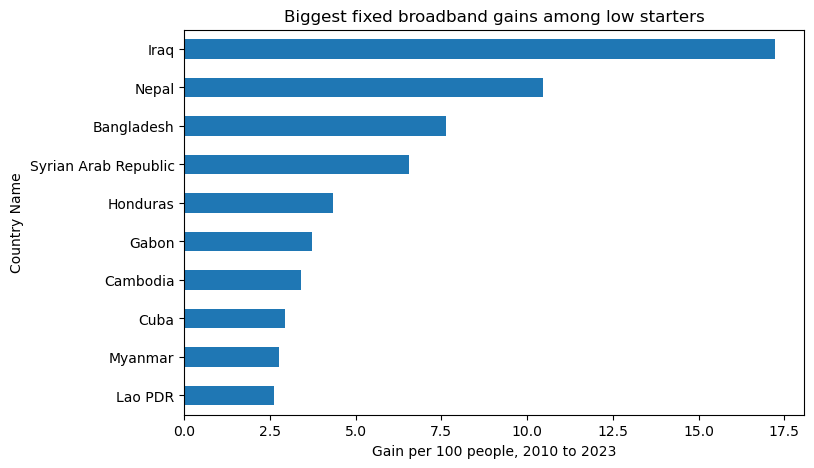

In [19]:
w = data.pivot(index="Country Name", columns="Year", values="fixed_broadband")[[2010, 2023]].dropna()
w["gain"] = w[2023] - w[2010]

cutoff = w[2010].quantile(0.25)          # bottom quarter in 2010
w["low_start"] = w[2010] <= cutoff

print("Top 10 overall:")
print(w.nlargest(10, "gain").round(1))
print("\nTop 10 among countries that started in the bottom quarter:")
print(w[w["low_start"]].nlargest(10, "gain").round(1))

top = w[w["low_start"]].nlargest(10, "gain")["gain"].sort_values()
top.plot(kind="barh", figsize=(8, 5), title="Biggest fixed broadband gains among low starters")
plt.xlabel("Gain per 100 people, 2010 to 2023")
plt.show()

                            servers_2010  servers_change  fixed_gain
Region                                                              
East Asia & Pacific                 16.7          1337.1        11.8
Europe & Central Asia              172.5         29001.9        12.3
Latin America & Caribbean           24.8           718.0        10.3
Middle East & North Africa           4.3           381.2         9.5
North America                     2481.3         40120.3         8.7
South Asia                           1.5           802.8         7.3
Sub-Saharan Africa                   0.4            37.6         0.5


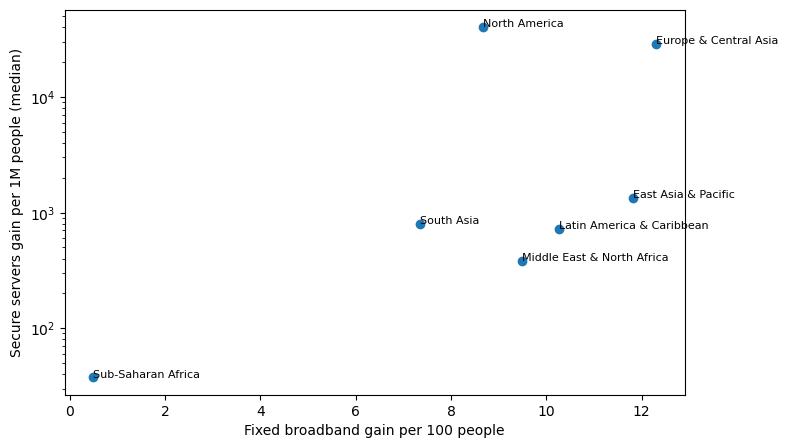

In [20]:
r = data.groupby(["Region", "Year"])[["secure_servers", "fixed_broadband"]].median()

q3 = pd.DataFrame({
    "servers_2010":    r["secure_servers"].xs(2010, level="Year"),
    "servers_change":  r["secure_servers"].xs(2023, level="Year") - r["secure_servers"].xs(2010, level="Year"),
    "fixed_gain":      r["fixed_broadband"].xs(2023, level="Year") - r["fixed_broadband"].xs(2010, level="Year"),
})
print(q3.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(q3["fixed_gain"], q3["servers_change"])
for region, row in q3.iterrows():
    ax.annotate(region, (row["fixed_gain"], row["servers_change"]), fontsize=8)
ax.set_xlabel("Fixed broadband gain per 100 people")
ax.set_ylabel("Secure servers gain per 1M people (median)")
ax.set_yscale("log")
plt.show()

In [21]:
indicators = ["secure_servers", "fixed_broadband", "mobile_cellular"]

# % of years (out of 14) missing, per country and indicator
gaps = data[indicators].isna().groupby(data["Country Name"]).mean() * 100
gaps["max_missing_pct"] = gaps.max(axis=1)

# countries missing at least half their years for any indicator
big_gaps = gaps[gaps["max_missing_pct"] >= 50].sort_values("max_missing_pct", ascending=False)
print(len(big_gaps), "countries with significant gaps")
print(big_gaps.round(0))

# flag them (rather than delete them)
data["data_gap_flag"] = data["Country Name"].map(gaps["max_missing_pct"] >= 50)

15 countries with significant gaps
                           secure_servers  fixed_broadband  mobile_cellular  \
Country Name                                                                  
American Samoa                        0.0            100.0            100.0   
Channel Islands                     100.0            100.0            100.0   
Guam                                  0.0             50.0            100.0   
Isle of Man                           0.0            100.0            100.0   
Korea, Dem. People's Rep.            29.0            100.0             14.0   
Kosovo                              100.0            100.0             86.0   
Northern Mariana Islands              0.0            100.0            100.0   
Sint Maarten (Dutch part)             0.0            100.0             86.0   
St. Martin (French part)              7.0            100.0            100.0   
Turks and Caicos Islands              0.0            100.0            100.0   
Naoero           

In [22]:
data.to_csv("cleaned_2010_2023.csv", index=False)

In [23]:
latest = data[data["Year"] == 2023]

for ind in ["secure_servers", "fixed_broadband", "mobile_cellular"]:
    s = latest.dropna(subset=[ind]).set_index("Country Name")[ind]
    print(f"\n=== {ind} (2023, {len(s)} countries with data) ===")
    print("TOP 10");    print(s.nlargest(10).round(1))
    print("BOTTOM 10"); print(s.nsmallest(10).round(1))


=== secure_servers (2023, 215 countries with data) ===
TOP 10
Country Name
British Virgin Islands    1982403.5
Cyprus                     557174.3
Belize                     405693.4
Denmark                    261262.4
Singapore                  228648.4
Netherlands                194962.9
United States              186721.3
Switzerland                163621.7
Finland                    153868.5
Ireland                    149934.2
Name: secure_servers, dtype: float64
BOTTOM 10
Country Name
Eritrea                      0.3
Chad                         1.2
Sudan                        2.1
Central African Republic     2.5
South Sudan                  3.8
Korea, Dem. People's Rep.    3.9
Niger                        4.7
Guinea-Bissau                6.5
Yemen, Rep.                  7.0
Haiti                        7.4
Name: secure_servers, dtype: float64

=== fixed_broadband (2023, 169 countries with data) ===
TOP 10
Country Name
Monaco           55.9
Andorra          51.7
Liechtenstein   

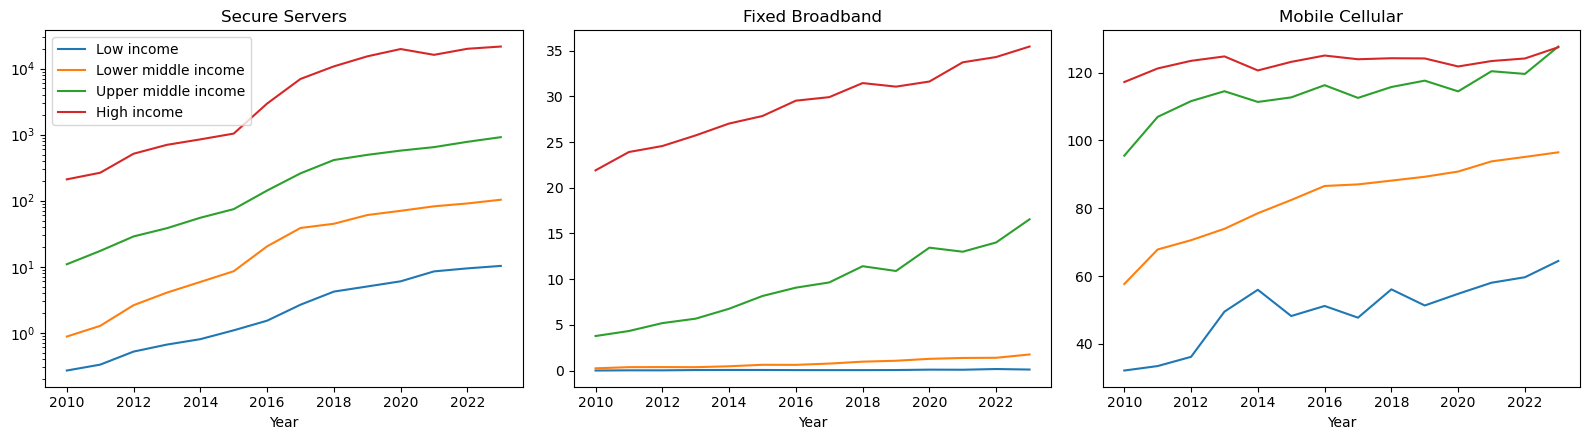

                     secure_servers  fixed_broadband  mobile_cellular
IncomeGroup                                                          
Low income                      0.3              0.0             32.1
Lower middle income             0.9              0.3             57.6
Upper middle income            10.9              3.8             95.5
High income                   210.4             21.9            117.2
                     secure_servers  fixed_broadband  mobile_cellular
IncomeGroup                                                          
Low income                     10.3              0.1             64.4
Lower middle income           103.5              1.8             96.5
Upper middle income           915.5             16.6            127.7
High income                 21564.8             35.4            127.5


In [24]:
import matplotlib.pyplot as plt

inds = ["secure_servers", "fixed_broadband", "mobile_cellular"]
order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
grp = data.groupby(["IncomeGroup", "Year"])[inds].median()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, ind in zip(axes, inds):
    for g in order:
        grp.loc[g][ind].plot(ax=ax, label=g)
    ax.set_title(ind.replace("_", " ").title())
    ax.set_xlabel("Year")
    if ind == "secure_servers":
        ax.set_yscale("log")
axes[0].legend()
plt.tight_layout()
plt.show()

print(grp.xs(2010, level="Year").loc[order].round(1))
print(grp.xs(2023, level="Year").loc[order].round(1))

In [25]:
reg = data.groupby(["Region", "Year"])[inds].median()
start, end = reg.xs(2010, level="Year"), reg.xs(2023, level="Year")
pct = ((end - start) / start * 100).round(0)

print("Start (2010)"); print(start.round(1))
print("End (2023)");   print(end.round(1))
print("% change");     print(pct)

Start (2010)
                            secure_servers  fixed_broadband  mobile_cellular
Region                                                                      
East Asia & Pacific                   16.7              2.7             78.9
Europe & Central Asia                172.5             21.6            110.8
Latin America & Caribbean             24.8              7.3            114.6
Middle East & North Africa             4.3              1.8             90.7
North America                       2481.3             31.6             91.7
South Asia                             1.5              1.0             58.3
Sub-Saharan Africa                     0.4              0.1             43.6
End (2023)
                            secure_servers  fixed_broadband  mobile_cellular
Region                                                                      
East Asia & Pacific                 1353.9             14.5            126.9
Europe & Central Asia              29174.4          

      fixed_broadband  mobile_cellular
Year                                  
2010             21.9             85.1
2023             35.3             63.0


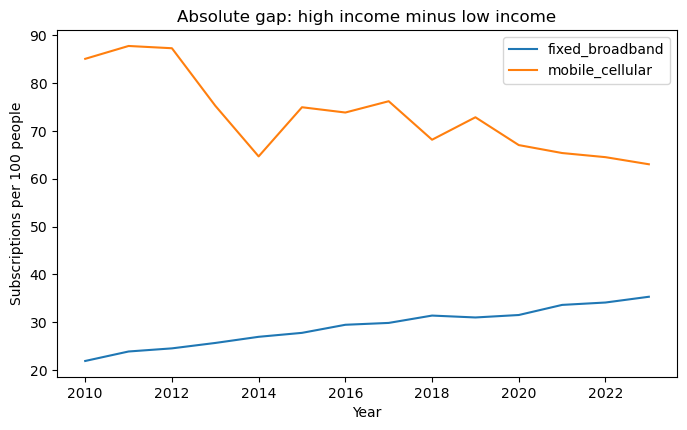

In [26]:
g = data.groupby(["IncomeGroup", "Year"])[inds].median()
gap = (g.xs("High income", level="IncomeGroup") - g.xs("Low income", level="IncomeGroup"))
print(gap.loc[[2010, 2023], ["fixed_broadband", "mobile_cellular"]].round(1))

gap[["fixed_broadband", "mobile_cellular"]].plot(figsize=(8, 4.5),
    title="Absolute gap: high income minus low income")
plt.ylabel("Subscriptions per 100 people")
plt.show()